### 시작하기

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import plotly.express as px
import plotly.graph_objects as go

In [8]:
import warnings
warnings.filterwarnings("ignore")

#data import
main_df=pd.read_csv("./netflix_titles.csv")
#main data를 미리 볼 수 있음
main_df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


In [8]:
#data columns info 각 컬럼의 정보 / 데이터 유형 및 누락 값 확인
print(main_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7787 non-null   object
 1   type          7787 non-null   object
 2   title         7787 non-null   object
 3   director      5398 non-null   object
 4   cast          7069 non-null   object
 5   country       7280 non-null   object
 6   date_added    7777 non-null   object
 7   release_year  7787 non-null   int64 
 8   rating        7780 non-null   object
 9   duration      7787 non-null   object
 10  listed_in     7787 non-null   object
 11  description   7787 non-null   object
dtypes: int64(1), object(11)
memory usage: 730.2+ KB
None


### 데이터 설명
- show_id: unique id of each show (not much of a use for us in this notebook)  

- type: The category of a show, can be either a Movie or a TV Show / 분류

- title: Name of the show / 제목

- director: Name of the director(s) of the show / 제작자

- cast: Name of actors and other cast of the show / 출연진

- country: Name of countries the show is available to watch on Netflix / 제작국가

- date_added: Date when the show was added on Netflix / 공개 날짜

- release_year: Release year of the show / 출시 연도

- rating: Show rating on netflix / 관람 등급

- duration: Time duration of the show / 작품 길이

- listed_in: Genre of the show / 해당 작품이 속한 부류

- description: Some text describing the show / 작품개요(설명)

In [9]:
# 수치형 정보 확인 
main_df.describe()

,release_year
count,7787.000000
mean,2013.932580
std,8.757395
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2018.000000
max,2021.000000


### 결측값 확인

<Axes: >

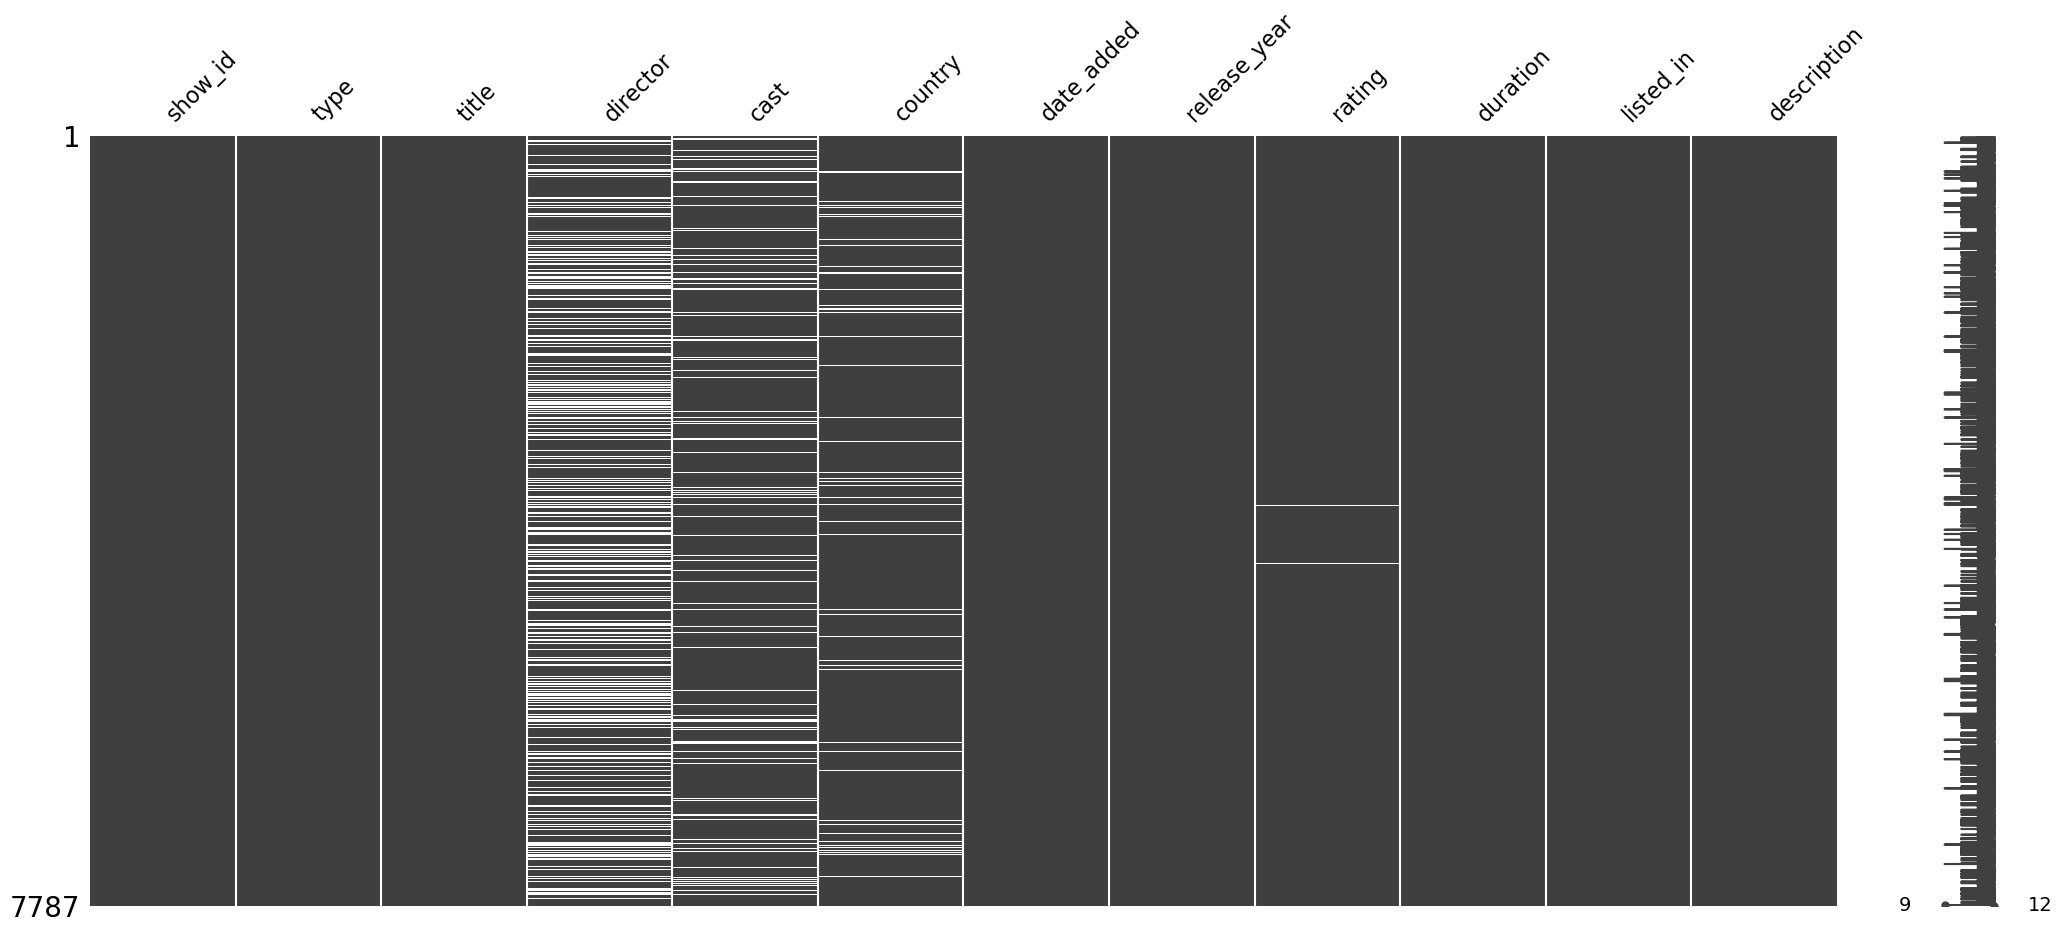

In [10]:
# 데이터 결측치 분포도 / missingno 패키지 활용 결측값 확인
msno.matrix(main_df)

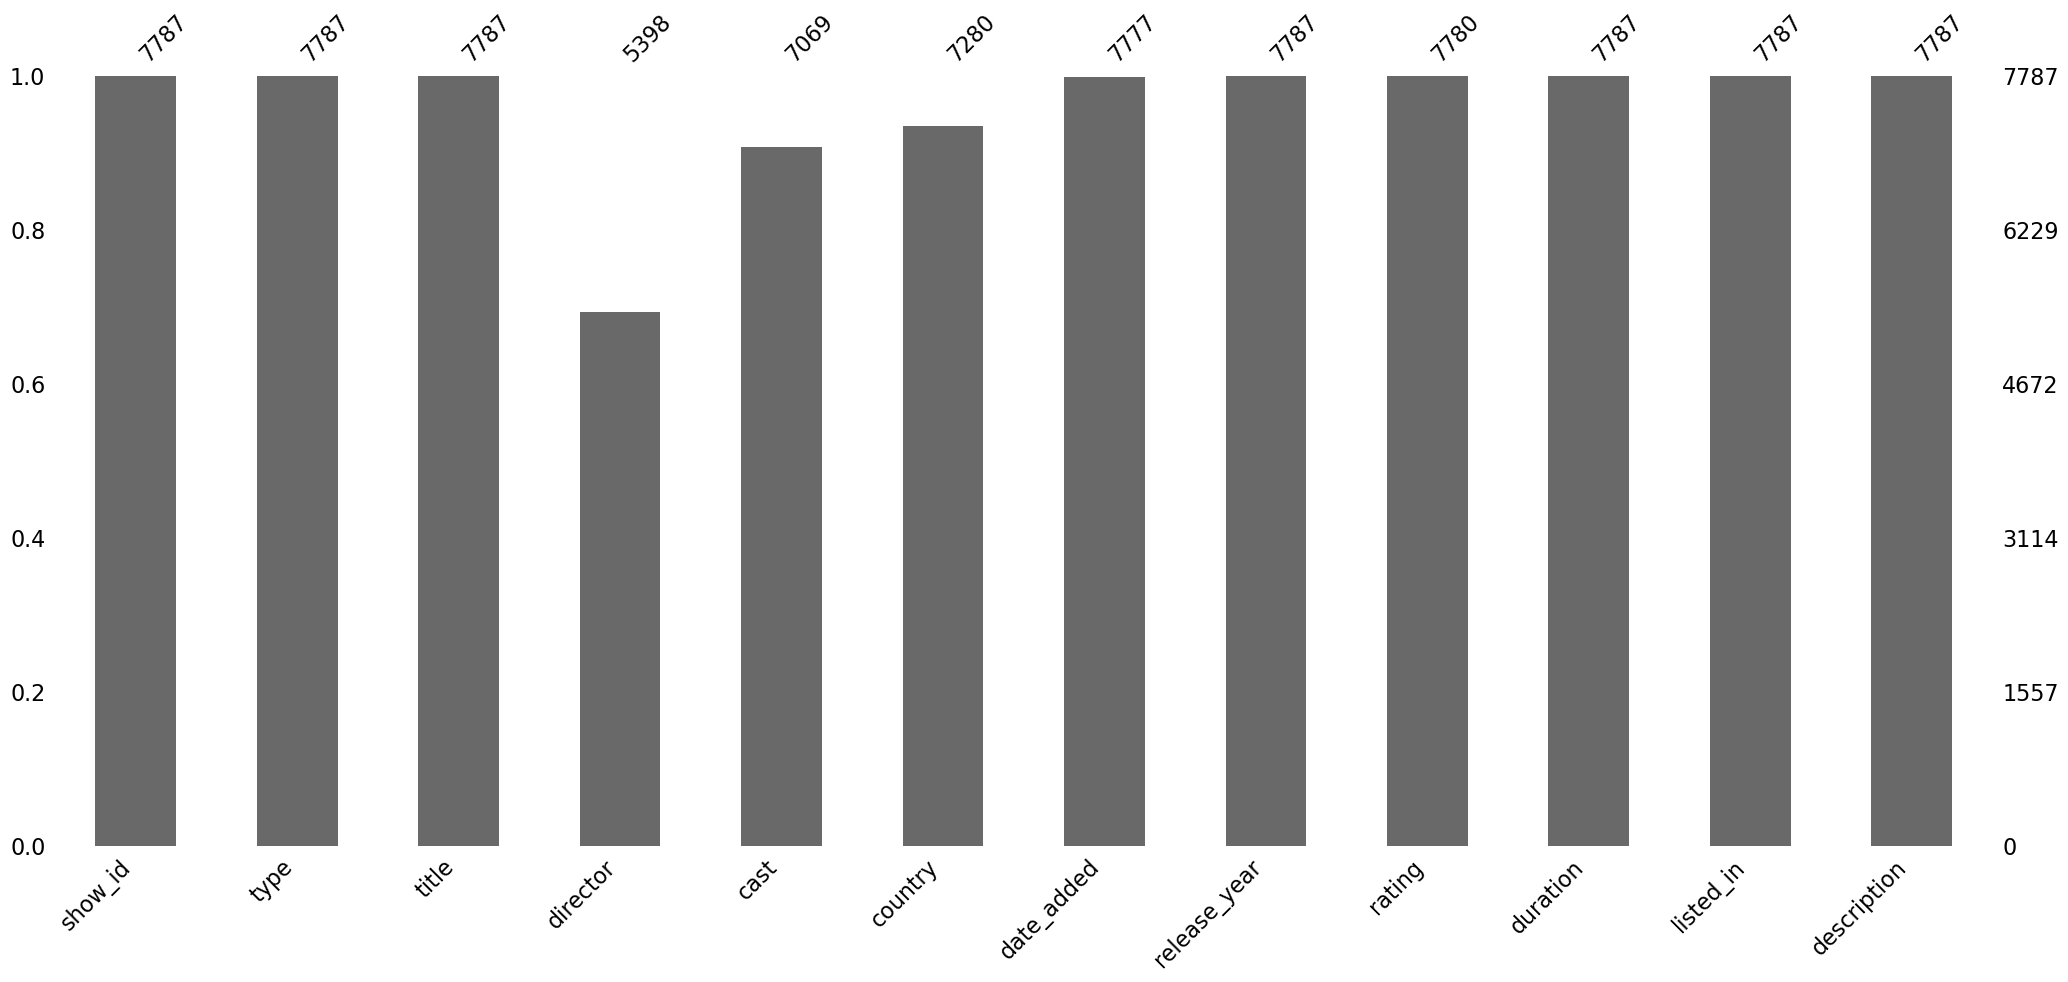

In [11]:
# 결측치 차트
msno.bar(main_df);

In [12]:
#결측치 비율 확인
for i in main_df.columns:
    null_rate = main_df[i].isna().sum() / len(main_df) * 100 
    if null_rate > 0 :
        print("{}'s null rate :{}%".format(i,round(null_rate,2)))

director's null rate :30.68%
cast's null rate :9.22%
country's null rate :6.51%
date_added's null rate :0.13%
rating's null rate :0.09%


In [13]:
#결측 데이터 수
main_df.isna().sum()

show_id            0
type               0
title              0
director        2389
cast             718
country          507
date_added        10
release_year       0
rating             7
duration           0
listed_in          0
description        0
dtype: int64

In [14]:
#유니크한 데이터 수 확인 / 각 컬럼별 데이터에서 데이터를 group by 하였을때의 카운트
main_df.nunique()

show_id         7787
type               2
title           7787
director        4049
cast            6831
country          681
date_added      1565
release_year      73
rating            14
duration         216
listed_in        492
description     7769
dtype: int64

### 데이터 전처리

In [15]:
# 중복 데이터 확인 / 중복 없음
main_df.duplicated().sum()

np.int64(0)

In [16]:
print(main_df.shape)

(7787, 12)


In [17]:
# 사용하지 않는 컬럼 삭제 
nf = main_df.drop(['title', 'director', 'cast', 'description'], axis=1)
nf.columns

Index(['show_id', 'type', 'country', 'date_added', 'release_year', 'rating',
       'duration', 'listed_in'],
      dtype='object')

In [18]:
print(nf.shape)
nf.head()

(7787, 8)


,show_id,type,country,date_added,release_year,rating,duration,listed_in
0,s1,TV Show,Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &..."
1,s2,Movie,Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies"
2,s3,Movie,Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies"
3,s4,Movie,United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi..."
4,s5,Movie,United States,"January 1, 2020",2008,PG-13,123 min,Dramas


### 결측치 처리

In [19]:
# country 컬럼은 대체 할 수 있는 값을 알기 어려우니 Unknown 으로 변경
nf['country'] = nf['country'].fillna("unknown")
nf['country'].isnull().sum()

np.int64(0)

In [20]:
#나머지 컬럼의 결측치는 비중이 매우 작기때문에 삭제
nf = nf.dropna().reset_index(drop = True)
nf.isnull().sum()

show_id         0
type            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

In [21]:
nf.shape

(7770, 8)

### 새로운 컬럼 생성 / 정리

In [22]:
nf['country'].unique()

array(['Brazil', 'Mexico', 'Singapore', 'United States', 'Turkey',
       'Egypt', 'India', 'Poland, United States', 'Thailand', 'Nigeria',
       'unknown', 'Norway, Iceland, United States', 'United Kingdom',
       'Japan', 'South Korea', 'Italy', 'Canada', 'Indonesia', 'Romania',
       'Spain', 'Iceland', 'South Africa, Nigeria', 'France',
       'United States, South Africa', 'Portugal, Spain',
       'Hong Kong, China, Singapore', 'United States, Germany',
       'South Africa, China, United States', 'Argentina',
       'United States, France, Serbia', 'Germany',
       'Denmark, France, Poland', 'Poland', 'Kenya',
       'New Zealand, United Kingdom', 'Pakistan', 'Australia',
       'Australia, United States', 'Mexico, United States',
       'United States, China', 'China, Hong Kong', 'Taiwan',
       'United States, United Kingdom', 'France, South Korea, Japan',
       'United States, Canada', 'United Kingdom, United States',
       'Netherlands, Denmark, South Africa', 'Canada

In [23]:
# 여러 국가가 들어있는 값이 있으므로, 제일 앞 국가명을 대표로 new_country 컬럼에 등록
nf['new_country'] = nf['country'].apply(lambda x: x.split(",")[0])

print(nf.shape)
nf.head(50)

(7770, 9)


,show_id,type,country,date_added,release_year,rating,duration,listed_in,new_country
0,s1,TV Show,Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",Brazil
1,s2,Movie,Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",Mexico
2,s3,Movie,Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies",Singapore
3,s4,Movie,United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...",United States
4,s5,Movie,United States,"January 1, 2020",2008,PG-13,123 min,Dramas,United States
5,s6,TV Show,Turkey,"July 1, 2017",2016,TV-MA,1 Season,"International TV Shows, TV Dramas, TV Mysteries",Turkey
6,s7,Movie,Egypt,"June 1, 2020",2019,TV-MA,95 min,"Horror Movies, International Movies",Egypt
7,s8,Movie,United States,"November 1, 2019",1997,R,119 min,Dramas,United States
8,s9,Movie,India,"April 1, 2019",2019,TV-14,118 min,"Horror Movies, International Movies",India
9,s10,Movie,India,"December 15, 2017",2008,TV-MA,143 min,"Horror Movies, International Movies, Thrillers",India


In [24]:
# date_added 컬럼 연도/월 분리하여 각각 저장
# year_added 컬럼 추가 하기
nf['year_added'] = nf['date_added'].apply(lambda x: x.split(" ")[-1])

# month_added 컬럼 추가 하기
nf['month_added'] = nf['date_added'].apply(lambda x: x.split(" ")[0])

# 추가한 컬럼 데이터 확인
nf.head()

,show_id,type,country,date_added,release_year,rating,duration,listed_in,new_country,year_added,month_added
0,s1,TV Show,Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",Brazil,2020,August
1,s2,Movie,Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",Mexico,2016,December
2,s3,Movie,Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies",Singapore,2018,December
3,s4,Movie,United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...",United States,2017,November
4,s5,Movie,United States,"January 1, 2020",2008,PG-13,123 min,Dramas,United States,2020,January


In [25]:
# 기존에 rating컬럼 값을 이용해서 시청 연령에 대한 값을 풀어서 저장 / 아마존에서 제공하는 등급 정보 기준
ratings_ages = {
    'TV-PG': 'Older Kids',
    'TV-MA': 'Adults',
    'TV-Y7-FV': 'Older Kids',
    'TV-Y7': 'Older Kids',
    'TV-14': 'Teens',
    'R': 'Adults',
    'TV-Y': 'Kids',
    'NR': 'Adults',
    'PG-13': 'Teens',
    'TV-G': 'Kids',
    'PG': 'Older Kids',
    'G': 'Kids',
    'UR': 'Adults',
    'NC-17': 'Adults'
}

nf['rating_ages'] = nf['rating'].replace(ratings_ages)
nf['rating_ages'].unique()


nf.head()

,show_id,type,country,date_added,release_year,rating,duration,listed_in,new_country,year_added,month_added,rating_ages
0,s1,TV Show,Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",Brazil,2020,August,Adults
1,s2,Movie,Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",Mexico,2016,December,Adults
2,s3,Movie,Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies",Singapore,2018,December,Adults
3,s4,Movie,United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...",United States,2017,November,Teens
4,s5,Movie,United States,"January 1, 2020",2008,PG-13,123 min,Dramas,United States,2020,January,Teens


In [26]:
nf['rating'].unique()

array(['TV-MA', 'R', 'PG-13', 'TV-14', 'TV-PG', 'NR', 'TV-G', 'TV-Y',
       'TV-Y7', 'PG', 'G', 'NC-17', 'TV-Y7-FV', 'UR'], dtype=object)

### 컬럼 타입 설정

In [27]:
# type 컬럼은 category로 변경 합니다.
nf['type'] = pd.Categorical(nf['type'])

# rating_ages 역시 category 로 변경 합니다.
nf['rating_ages'] = pd.Categorical(nf['rating_ages'], categories=['Kids', 'Older Kids', 'Teens', 'Adults'])

# Year_added 는 numaric type으로 변경 합니다. 그래야 released_year 데이터와 비교 할 수 있겠죠.
nf['year_added'] = pd.to_numeric(nf['year_added'])

nf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7770 entries, 0 to 7769
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   show_id       7770 non-null   object  
 1   type          7770 non-null   category
 2   country       7770 non-null   object  
 3   date_added    7770 non-null   object  
 4   release_year  7770 non-null   int64   
 5   rating        7770 non-null   object  
 6   duration      7770 non-null   object  
 7   listed_in     7770 non-null   object  
 8   new_country   7770 non-null   object  
 9   year_added    7770 non-null   int64   
 10  month_added   7770 non-null   object  
 11  rating_ages   7770 non-null   category
dtypes: category(2), int64(2), object(8)
memory usage: 622.7+ KB


### 데이터 시각화로 데이터 확인

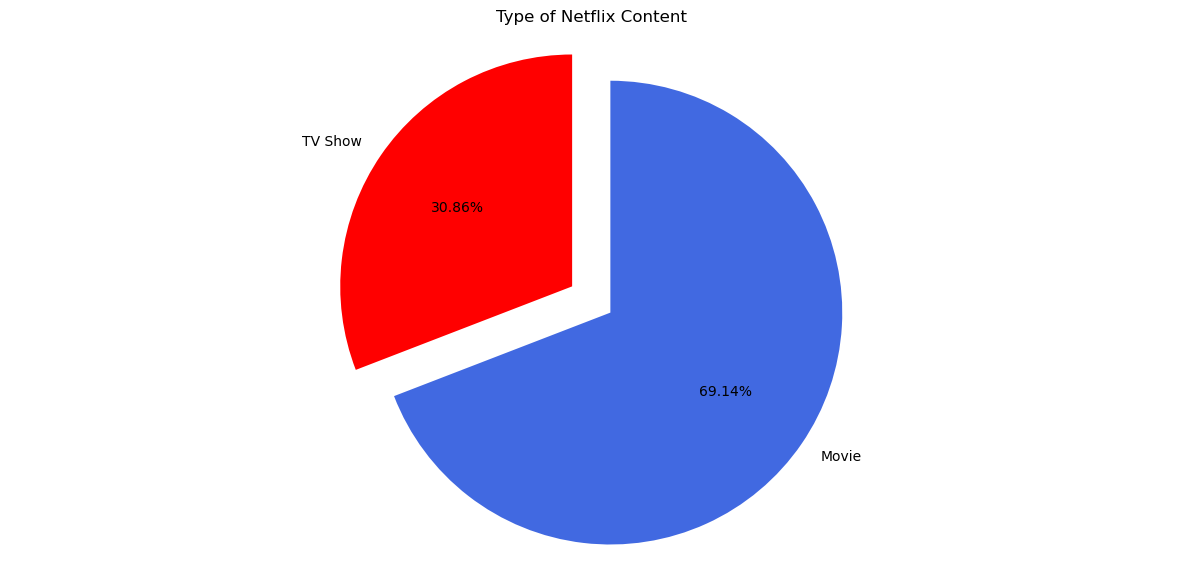

In [28]:
# 넷플릭스내에 TV Show와 Movie의 비율을 확인
plt.figure(figsize=(15, 7))
labels=['TV Show', 'Movie']
plt.pie(nf['type'].value_counts().sort_values(),labels=labels,explode=[0.1,0.1],
        autopct='%1.2f%%',colors=['red','royalblue'], startangle=90)
plt.title('Type of Netflix Content')
plt.axis('equal')
plt.show()

In [29]:
#  TV Show 와 Movie 두개의 dataframe을 각각 만들어서 각각의 시청 연령별 데이터 확인
df_tv = nf[nf["type"] == "TV Show"]
df_movies = nf[nf["type"] == "Movie"]

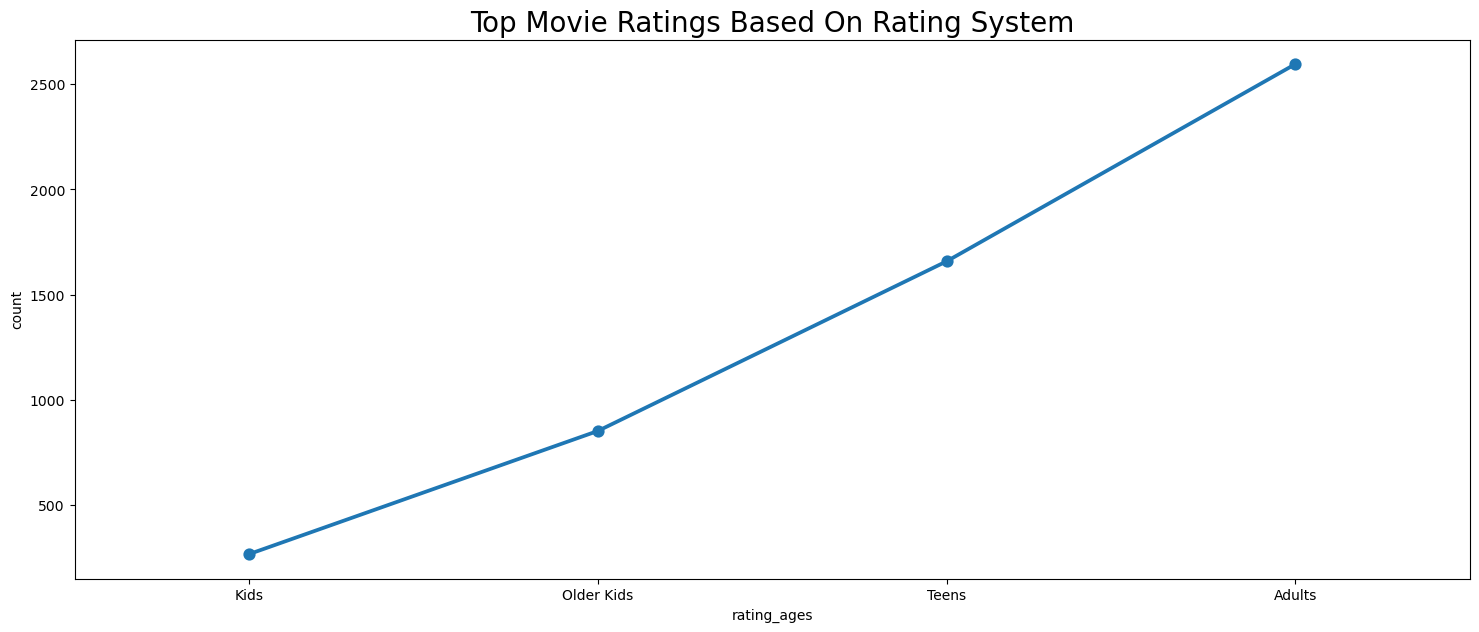

In [30]:
# Movie의 시청 연령별 컨텐츠 건수를 확인
movie_ratings = df_movies.groupby(['rating_ages'])['show_id'].count().reset_index(name='count').sort_values(by='count',ascending=False)
fig_dims = (18,7)
fig, ax = plt.subplots(figsize=fig_dims)  
sns.pointplot(x='rating_ages',y='count',data=movie_ratings)
plt.title('Top Movie Ratings Based On Rating System',size='20')
plt.show()

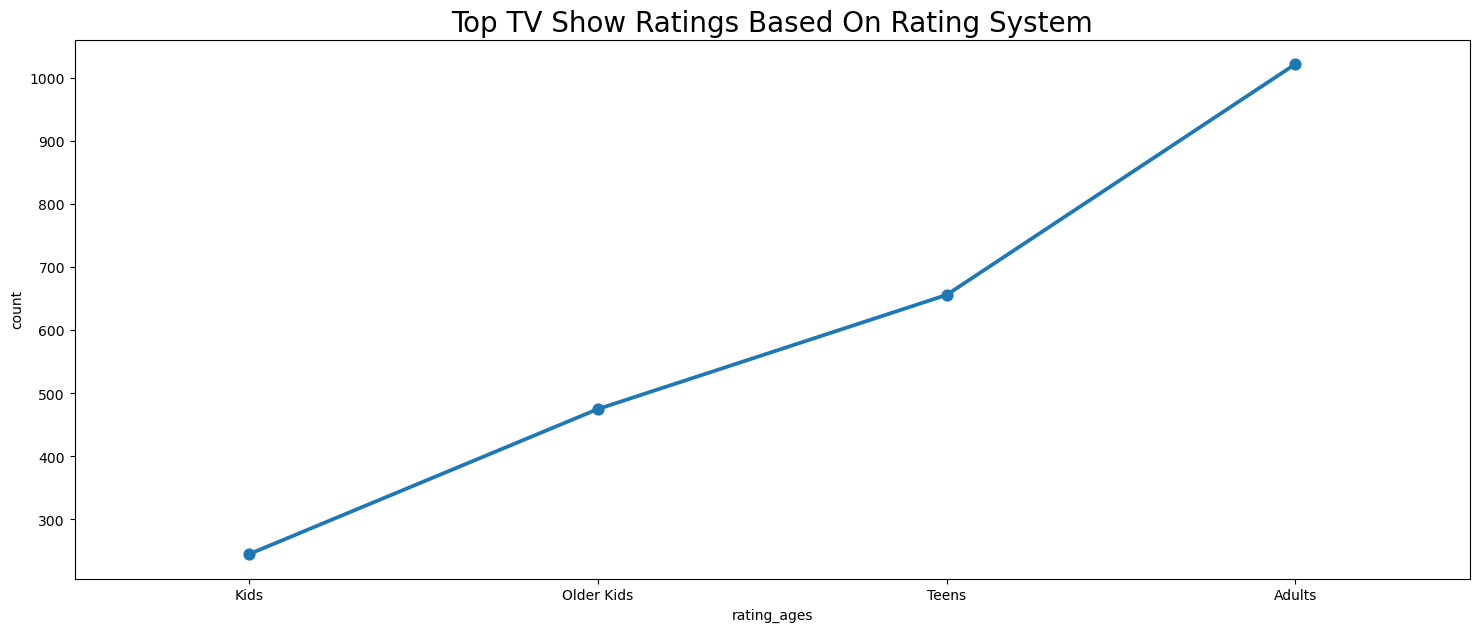

In [31]:
tv_ratings = df_tv.groupby(['rating_ages'])['show_id'].count().reset_index(name='count').sort_values(by='count',ascending=False)
fig_dims = (18,7)
fig, ax = plt.subplots(figsize=fig_dims)  
sns.pointplot(x='rating_ages',y='count',data=tv_ratings)
plt.title('Top TV Show Ratings Based On Rating System',size='20')
plt.show()

 #### TV Show와 Movie 전체 데이터를 가지고 rating 과 target_ages를 묶어서 각 rating이 어떤 target_ages에 속하고, 
 #### 각 건수가 어떻게 되는지를 시각화 하기위한 내부 function을 만들고, 이 function을 이용하여 출력하는 코드를 작성

In [32]:
# 함수 생성
def generate_rating_df(nf):
    rating_df = nf.groupby(['rating', 'rating_ages']).agg({'show_id': 'count'}).reset_index()
    rating_df = rating_df[rating_df['show_id'] != 0]
    rating_df.columns = ['rating', 'rating_ages', 'counts']
    rating_df = rating_df.sort_values('rating_ages')
    return rating_df
    
# 시각화 코드
rating_df = generate_rating_df(nf)
fig = px.bar(rating_df, x='rating', y='counts', color='rating_ages', title='Ratings of Movies And TV Shows Based On Target Age Groups',  labels={'counts':'COUNT', 'rating':'RATINGS', 'target_ages':'TARGET AGE GROUPS' })
fig.show()

### 넷플릭스 #1 문제 년도별 컨텐츠 등록 수 시각화

In [ ]:
import pandas as pd
import plotly.graph_objects as go

# 1) year_added 요약 함수 (버전 차이/rename 문제 방지)
def year_count_table(df, year_col="year_added"):
    tmp = df[year_col].value_counts().reset_index()
    # pandas 버전 상관없이 컬럼명 강제 지정
    tmp.columns = ["year_added", "count"]

    # year_added를 숫자로 변환(정렬/그래프 안정화)
    tmp["year_added"] = pd.to_numeric(tmp["year_added"], errors="coerce")
    tmp = tmp.dropna(subset=["year_added"])
    tmp["year_added"] = tmp["year_added"].astype(int)

    # 연도순 정렬
    tmp = tmp.sort_values("year_added")

    # 퍼센트 계산
    tmp["percent"] = tmp["count"] / tmp["count"].sum() * 100
    return tmp

# 2) 전체 / TV / Movie 테이블 만들기
df_content = year_count_table(nf)
df_tv1 = year_count_table(df_tv)
df_movies1 = year_count_table(df_movies)

# 3) Plotly 그래프
t1 = go.Scatter(
    x=df_movies1["year_added"], y=df_movies1["count"],
    mode="lines+markers", name="Movies",
    marker=dict(color="royalblue")
)

t2 = go.Scatter(
    x=df_tv1["year_added"], y=df_tv1["count"],
    mode="lines+markers", name="TV Shows",
    marker=dict(color="red")
)

t3 = go.Scatter(
    x=df_content["year_added"], y=df_content["count"],
    mode="lines+markers", name="Total Contents",
    marker=dict(color="black")
)

layout = go.Layout(
    title="Content added over the years",
    xaxis=dict(title="Year Added"),
    yaxis=dict(title="Count"),
    legend=dict(x=0.1, y=1.15, orientation="h")
)

fig = go.Figure(data=[t1, t2, t3], layout=layout)
fig.show()


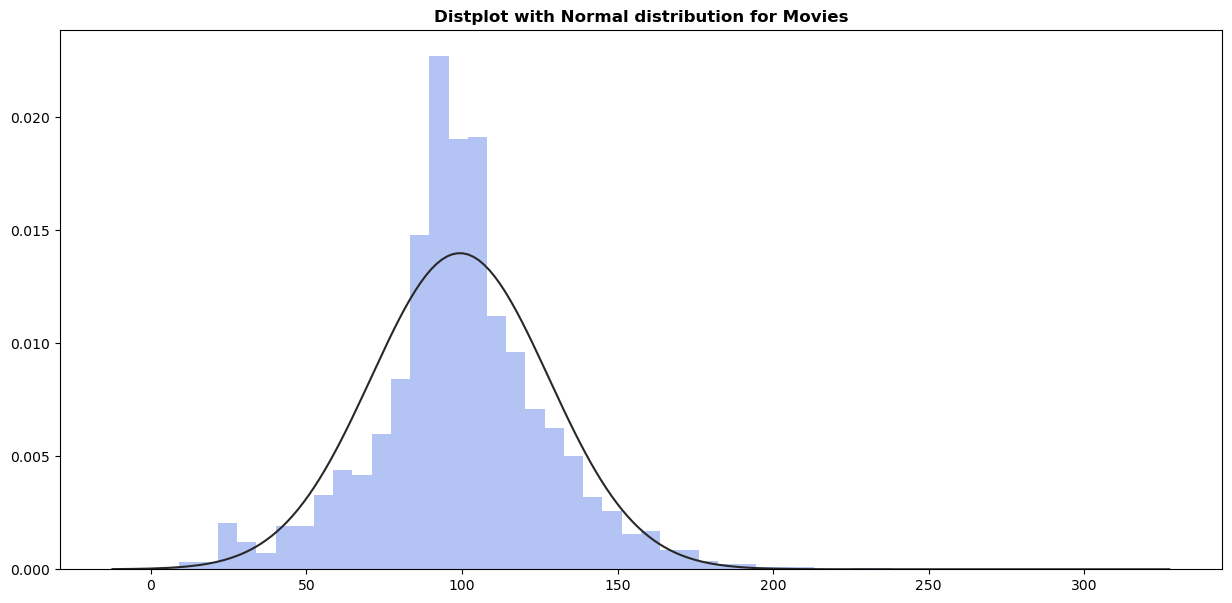

In [47]:
from scipy.stats import norm

plt.figure(figsize=(15,7))
sns.distplot(df_movies['duration'].str.extract('(\d+)'),
             fit=norm,kde=False, color=['royalblue'])
plt.title('Distplot with Normal distribution for Movies',fontweight="bold")
plt.show()

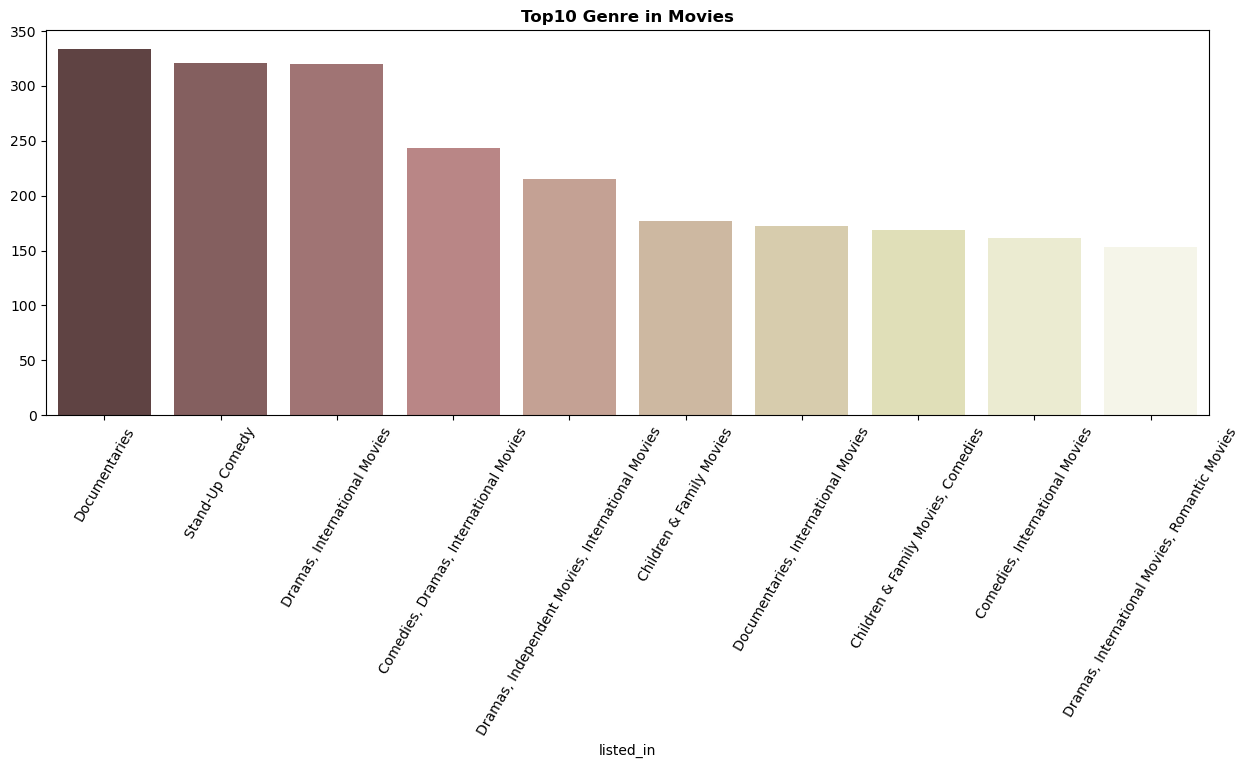

In [48]:
plt.figure(figsize=(15,5))
sns.barplot(x = df_movies["listed_in"].value_counts().head(10).index,
            y = df_movies["listed_in"].value_counts().head(10).values,palette="pink")
plt.xticks(rotation=60)
plt.title("Top10 Genre in Movies",fontweight="bold")
plt.show()

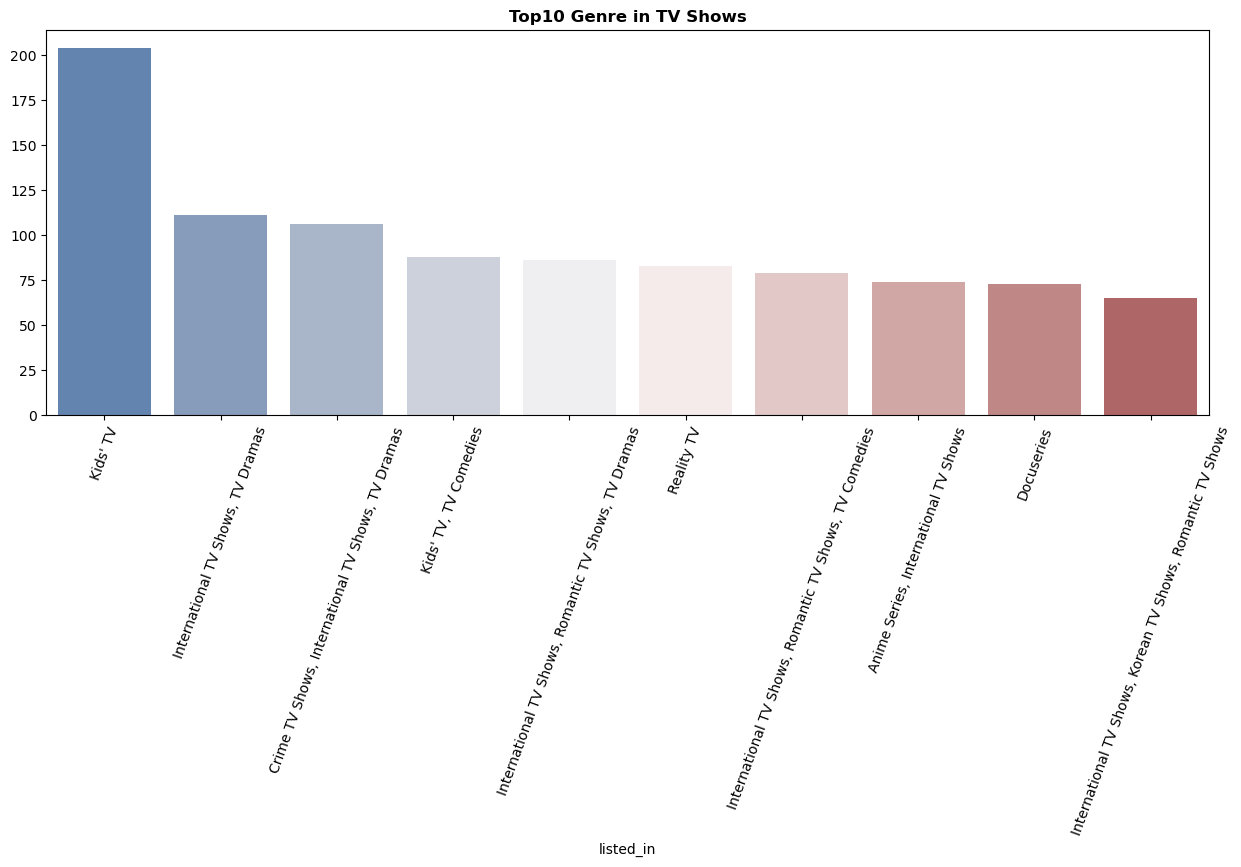

In [49]:
plt.figure(figsize=(15,5))
sns.barplot(x = df_tv["listed_in"].value_counts().head(10).index,
            y = df_tv["listed_in"].value_counts().head(10).values,palette="vlag")
plt.xticks(rotation=70)
plt.title("Top10 Genre in TV Shows",fontweight="bold")
plt.show()

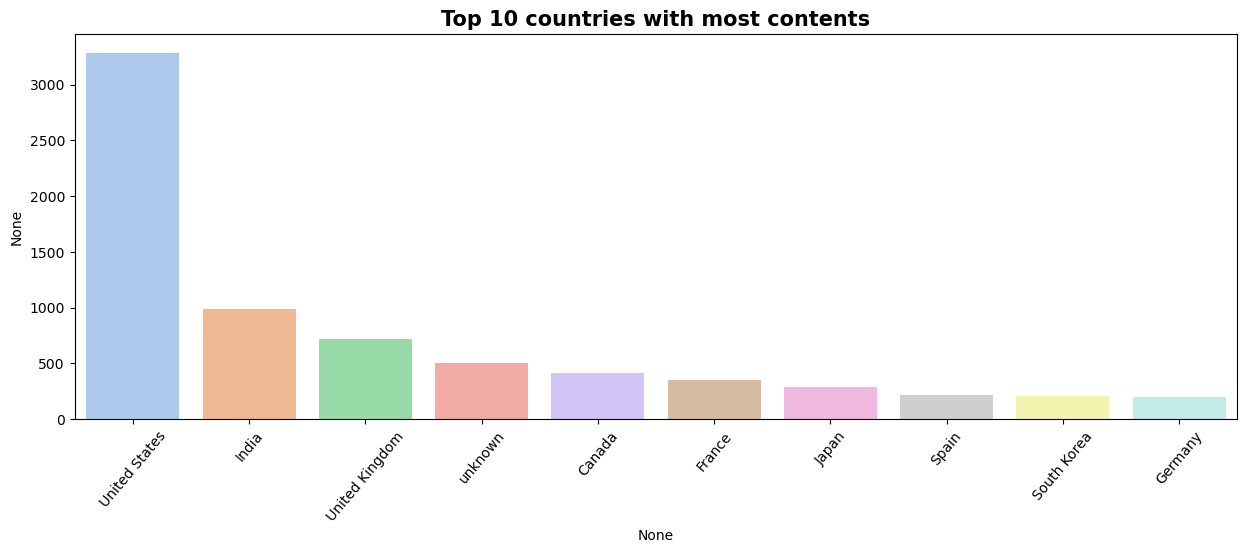

In [50]:
from collections import Counter
country_data =  nf['country']
country_count = pd.Series(dict(Counter(','.join(country_data).replace(' ,',',').replace(
    ', ',',').split(',')))).sort_values(ascending=False)
top20country = country_count.head(10)

plt.figure(figsize=(15,5))
sns.barplot(x= top20country.index, y=top20country, palette="pastel")
plt.xticks(rotation=50)
plt.title('Top 10 countries with most contents', fontsize=15, fontweight='bold')
plt.show()

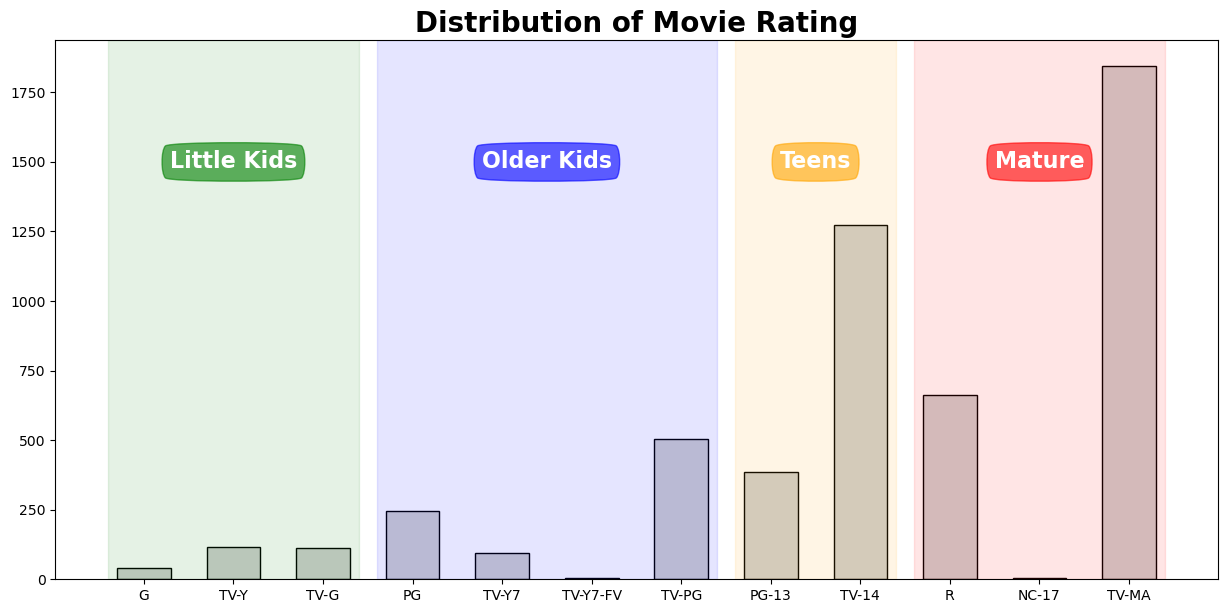

In [51]:
rating_order_movie =  ['G', 'TV-Y', 'TV-G', 'PG', 'TV-Y7', 'TV-Y7-FV', 'TV-PG', 'PG-13', 'TV-14', 'R', 'NC-17', 'TV-MA']
rating_order_tv =  [ 'TV-Y', 'TV-G', 'TV-Y7', 'TV-Y7-FV', 'TV-PG', 'TV-14', 'R', 'TV-MA']
movie_rating = df_movies['rating'].value_counts()[rating_order_movie]
tv_rating = df_tv['rating'].value_counts()[rating_order_tv].fillna(0)
def rating_barplot(data, title, height, h_lim=None):
    fig, ax = plt.subplots(1,1, figsize=(15, 7))
    if h_lim :
        ax.set_ylim(0, h_lim)
    ax.bar(data.index, data,  color="#d0d0d0", width=0.6, edgecolor='black')

    color =  ['green',  'blue',  'orange',  'red']
    span_range = [[0, 2], [3,  6], [7, 8], [9, 11]]

    for idx, sub_title in enumerate(['Little Kids', 'Older Kids', 'Teens', 'Mature']):
        ax.annotate(sub_title,
                    xy=(sum(span_range[idx])/2 ,height),
                    xytext=(0,0), textcoords='offset points',
                    va="center", ha="center",
                    color="w", fontsize=16, fontweight='bold',
                    bbox=dict(boxstyle='round4', pad=0.4, color=color[idx], alpha=0.6))
        ax.axvspan(span_range[idx][0]-0.4,span_range[idx][1]+0.4,  color=color[idx], alpha=0.1)

    ax.set_title(f'Distribution of {title} Rating', fontsize=20, fontweight='bold', position=(0.5, 1.0+0.03))
    plt.show()

rating_barplot(movie_rating,'Movie', 1500)

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1) 데이터 불러오기
df = pd.read_csv("netflix_titles.csv")

# 2) 결측/공백 정리
df["country"] = df["country"].fillna("Unknown").str.strip()
df["listed_in"] = df["listed_in"].fillna("Unknown").str.strip()

# 3) 멀티값 컬럼 쪼개기(국가/장르)
df_country = df.assign(country=df["country"].str.split(",")).explode("country")
df_country["country"] = df_country["country"].str.strip()

df_genre = df.assign(listed_in=df["listed_in"].str.split(",")).explode("listed_in")
df_genre["listed_in"] = df_genre["listed_in"].str.strip()


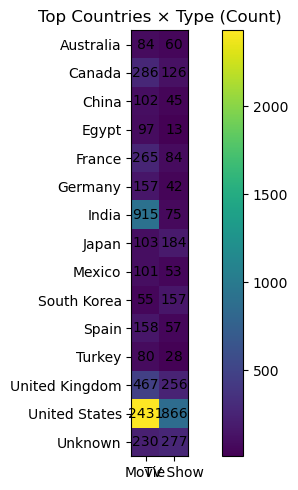

In [57]:
# 상위 15개 국가만 (너무 많으면 보기 어려움)
top_countries = df_country["country"].value_counts().head(15).index

heat = (df_country[df_country["country"].isin(top_countries)]
        .pivot_table(index="country", columns="type", values="title",
                     aggfunc="count", fill_value=0))

plt.figure(figsize=(7, 5))
plt.imshow(heat.values)  # 색으로 표현
plt.colorbar()

plt.xticks(range(len(heat.columns)), heat.columns)
plt.yticks(range(len(heat.index)), heat.index)
plt.title("Top Countries × Type (Count)")

# 각 칸에 숫자 쓰기(가독성 최고)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        plt.text(j, i, heat.iloc[i, j], ha="center", va="center", color="black")

plt.tight_layout()
plt.show()


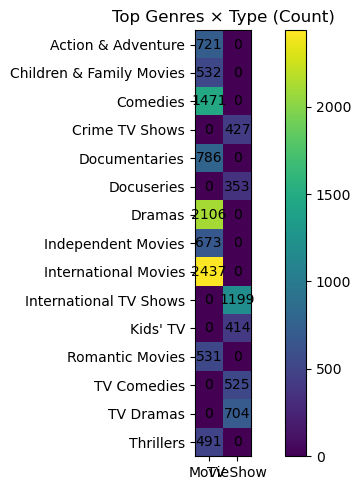

In [58]:
top_genres = df_genre["listed_in"].value_counts().head(15).index

heat2 = (df_genre[df_genre["listed_in"].isin(top_genres)]
         .pivot_table(index="listed_in", columns="type", values="title",
                      aggfunc="count", fill_value=0))

plt.figure(figsize=(7, 5))
plt.imshow(heat2.values)
plt.colorbar()

plt.xticks(range(len(heat2.columns)), heat2.columns)
plt.yticks(range(len(heat2.index)), heat2.index)
plt.title("Top Genres × Type (Count)")

for i in range(heat2.shape[0]):
    for j in range(heat2.shape[1]):
        plt.text(j, i, heat2.iloc[i, j], ha="center", va="center", color="black")

plt.tight_layout()
plt.show()


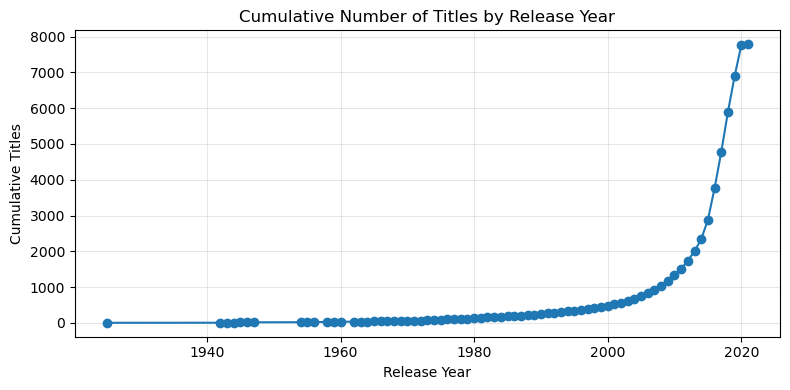

In [59]:
# 연도별 개수
year_counts = (df.groupby("release_year")["title"]
               .count()
               .sort_index())

# 누적합
year_cum = year_counts.cumsum()

plt.figure(figsize=(8, 4))
plt.plot(year_cum.index, year_cum.values, marker="o")
plt.title("Cumulative Number of Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Cumulative Titles")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


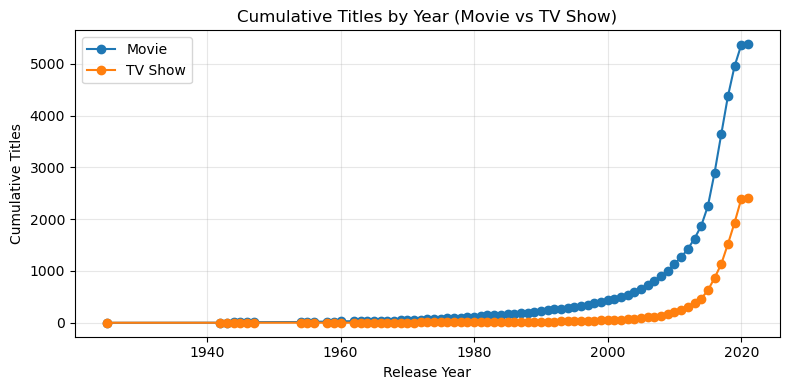

In [60]:
year_type = (df.groupby(["release_year", "type"])["title"]
             .count()
             .unstack(fill_value=0)
             .sort_index())

year_type_cum = year_type.cumsum()

plt.figure(figsize=(8, 4))
plt.plot(year_type_cum.index, year_type_cum["Movie"], marker="o", label="Movie")
plt.plot(year_type_cum.index, year_type_cum["TV Show"], marker="o", label="TV Show")
plt.title("Cumulative Titles by Year (Movie vs TV Show)")
plt.xlabel("Release Year")
plt.ylabel("Cumulative Titles")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [67]:
# ! pip install geopandas

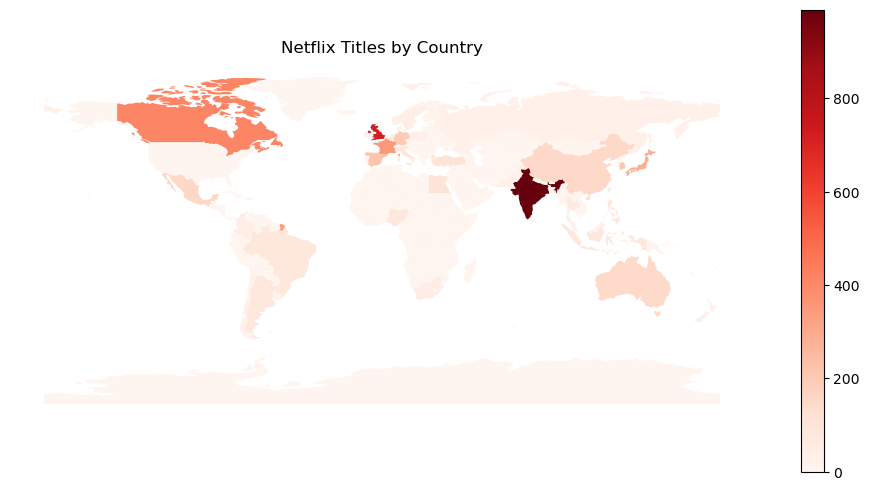

In [69]:
import geopandas as gpd
import matplotlib.pyplot as plt

# 1️⃣ 자연지리 지도 파일 로드 (직접 경로!)
world = gpd.read_file("ne_110m_admin_0_countries/ne_110m_admin_0_countries.shp")

# 2️⃣ 나라별 넷플릭스 콘텐츠 수
country_counts = (
    df_country["country"]
    .value_counts()
    .rename_axis("country")
    .reset_index(name="count")
)

# 3️⃣ 지도 + 넷플릭스 데이터 병합
merged = world.merge(
    country_counts,
    left_on="NAME",      # Natural Earth 국가명
    right_on="country",  # 넷플릭스 국가명
    how="left"
)

merged["count"] = merged["count"].fillna(0)

# 4️⃣ 지도 시각화
fig, ax = plt.subplots(figsize=(12, 6))
merged.plot(
    column="count",
    ax=ax,
    legend=True,
    cmap="Reds",
    missing_kwds={"color": "lightgrey"}
)

ax.set_title("Netflix Titles by Country")
ax.set_axis_off()
plt.show()


In [63]:
! pip install networkx

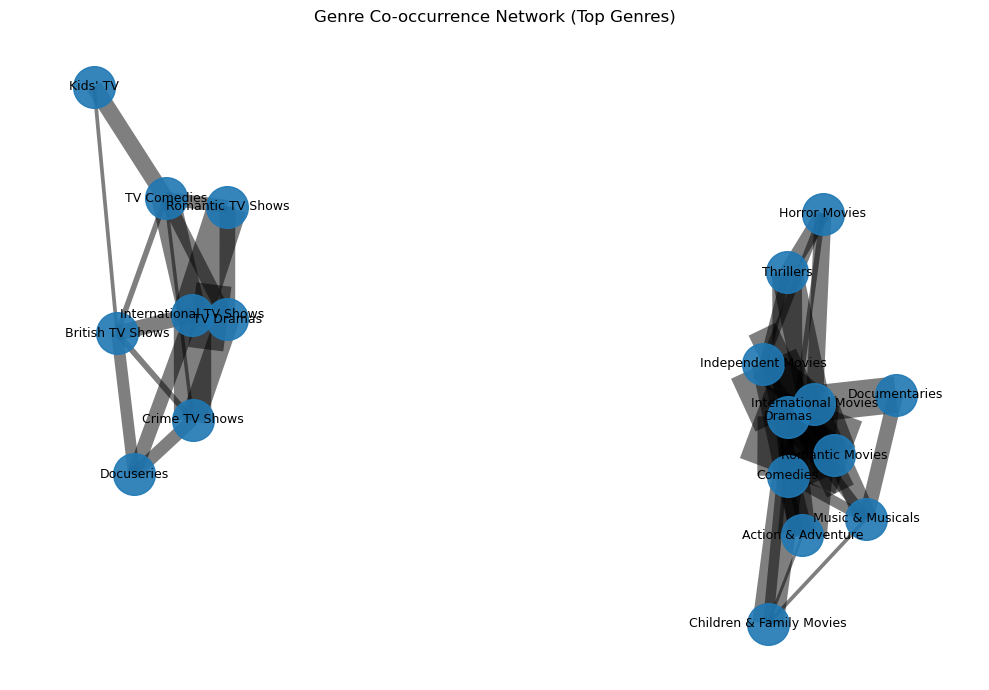

In [64]:
import networkx as nx
from itertools import combinations

# 장르 리스트 만들기
genre_lists = df["listed_in"].fillna("").apply(lambda s: [g.strip() for g in s.split(",") if g.strip()])

# 동시 등장 쌍 집계 (너무 무거워질 수 있어서 상위 장르만 제한 추천)
topN = 20
top_genre_set = set(df_genre["listed_in"].value_counts().head(topN).index)

pair_counts = {}
for genres in genre_lists:
    genres = [g for g in genres if g in top_genre_set]
    genres = sorted(set(genres))
    for a, b in combinations(genres, 2):
        pair_counts[(a, b)] = pair_counts.get((a, b), 0) + 1

# 그래프 만들기
G = nx.Graph()
for (a, b), w in pair_counts.items():
    if w >= 20:  # 너무 약한 연결은 제거(수업용 가독성)
        G.add_edge(a, b, weight=w)

plt.figure(figsize=(10, 7))
pos = nx.spring_layout(G, seed=1, k=0.6)

# 노드
nx.draw_networkx_nodes(G, pos, node_size=900, alpha=0.9)

# 엣지(굵기=연결 강도)
weights = [G[u][v]["weight"] for u, v in G.edges()]
# 너무 두꺼워지지 않게 스케일
scaled = [w / 10 for w in weights]
nx.draw_networkx_edges(G, pos, width=scaled, alpha=0.5)

# 라벨
nx.draw_networkx_labels(G, pos, font_size=9)

plt.title("Genre Co-occurrence Network (Top Genres)")
plt.axis("off")
plt.tight_layout()
plt.show()


In [70]:
import pandas as pd

df_country = nf.assign(
    country=nf["country"].fillna("Unknown").str.split(",")
).explode("country")

df_country["country"] = df_country["country"].str.strip()

In [71]:
import plotly.express as px

# 나라별 타이틀 수 집계
country_counts = (
    df_country[df_country["country"].ne("Unknown")]
    .groupby("country")
    .size()
    .reset_index(name="count")
)

fig = px.choropleth(
    country_counts,
    locations="country",
    locationmode="country names",
    color="count",
    color_continuous_scale="Reds",
    title="Netflix Titles by Country",
)

fig.update_layout(
    margin=dict(l=0, r=0, t=60, b=0)
)

fig.show()


In [74]:
import plotly.express as px

# 나라×타입 집계
ct = (
    df_country[df_country["country"].ne("Unknown")]
    .pivot_table(index="country", columns="type", values="show_id", aggfunc="count", fill_value=0)
    .reset_index()
)

# Total 계산
ct["Total"] = ct.get("Movie", 0) + ct.get("TV Show", 0)

# choropleth에 넣을 데이터
map_df = ct.rename(columns={"country": "Country"})

fig = px.choropleth(
    map_df,
    locations="Country",
    locationmode="country names",
    color="Total",
    color_continuous_scale="Reds",
    hover_name="Country",
    hover_data={
        "Total": True,
        "Movie": True,
        "TV Show": True,
        "Country": False
    },
    title="Netflix Titles by Country (Total / Movie / TV Show)"
)

fig.update_layout(margin=dict(l=0, r=0, t=60, b=0))
fig.show()


In [75]:
import pandas as pd
import numpy as np
import plotly.express as px

# 1) date_added -> datetime 변환 (넷플릭스는 보통 "September 9, 2019" 형태)
nf2 = nf.copy()
nf2["date_added"] = pd.to_datetime(nf2["date_added"], errors="coerce")

# 2) 추가된 연도(슬라이더용)
nf2["year_added"] = nf2["date_added"].dt.year

# year_added 없는 행 제거
nf2 = nf2.dropna(subset=["year_added"])
nf2["year_added"] = nf2["year_added"].astype(int)

# 3) 나라 explode (여러 나라인 경우 쪼개기)
df_country = nf2.assign(
    country=nf2["country"].fillna("Unknown").str.split(",")
).explode("country")
df_country["country"] = df_country["country"].str.strip()

# Unknown 제거(지도 인식 불가)
df_country = df_country[df_country["country"].ne("Unknown")]


In [76]:
# year_added, country, type 기준으로 show_id 개수 세기
agg = (
    df_country
    .groupby(["year_added", "country", "type"])["show_id"]
    .nunique()
    .reset_index(name="count")
)

# Movie / TV Show를 컬럼으로 펼치기
wide = (
    agg.pivot_table(index=["year_added", "country"], columns="type", values="count", fill_value=0)
    .reset_index()
)

# Total 계산 (컬럼명이 없을 수도 있어서 get으로 안전하게)
wide["Movie"] = wide.get("Movie", 0)
wide["TV Show"] = wide.get("TV Show", 0)
wide["Total"] = wide["Movie"] + wide["TV Show"]


In [77]:
fig = px.choropleth(
    wide,
    locations="country",
    locationmode="country names",
    color="Total",
    animation_frame="year_added",          # ✅ 연도 슬라이더 핵심
    hover_name="country",
    hover_data={
        "Total": True,
        "Movie": True,
        "TV Show": True,
        "year_added": False,
        "country": False
    },
    color_continuous_scale="Reds",
    range_color=(0, wide["Total"].max()),  # ✅ 연도 바뀌어도 색 기준 유지(중요!)
    title="Netflix Titles Added by Country (Animated by Year)"
)

fig.update_layout(
    margin=dict(l=0, r=0, t=60, b=0),
    geo=dict(showframe=False, showcoastlines=True)
)

fig.show()


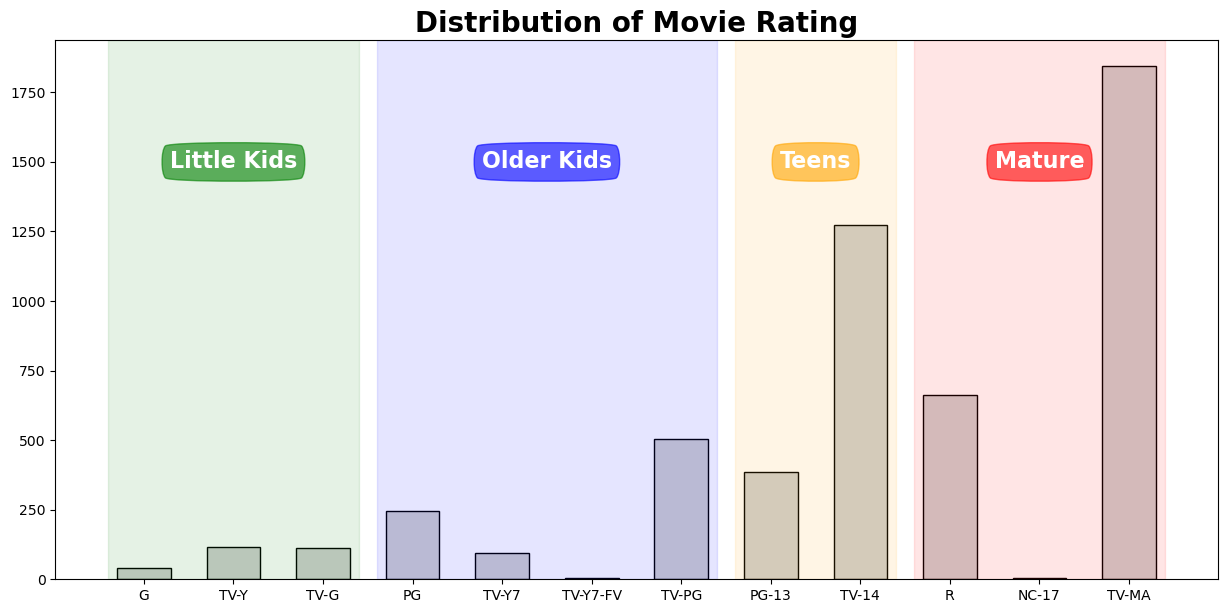

In [78]:
rating_order_movie =  ['G', 'TV-Y', 'TV-G', 'PG', 'TV-Y7', 'TV-Y7-FV', 'TV-PG', 'PG-13', 'TV-14', 'R', 'NC-17', 'TV-MA']
rating_order_tv =  [ 'TV-Y', 'TV-G', 'TV-Y7', 'TV-Y7-FV', 'TV-PG', 'TV-14', 'R', 'TV-MA']
movie_rating = df_movies['rating'].value_counts()[rating_order_movie]
tv_rating = df_tv['rating'].value_counts()[rating_order_tv].fillna(0)
def rating_barplot(data, title, height, h_lim=None):
    fig, ax = plt.subplots(1,1, figsize=(15, 7))
    if h_lim :
        ax.set_ylim(0, h_lim)
    ax.bar(data.index, data,  color="#d0d0d0", width=0.6, edgecolor='black')

    color =  ['green',  'blue',  'orange',  'red']
    span_range = [[0, 2], [3,  6], [7, 8], [9, 11]]

    for idx, sub_title in enumerate(['Little Kids', 'Older Kids', 'Teens', 'Mature']):
        ax.annotate(sub_title,
                    xy=(sum(span_range[idx])/2 ,height),
                    xytext=(0,0), textcoords='offset points',
                    va="center", ha="center",
                    color="w", fontsize=16, fontweight='bold',
                    bbox=dict(boxstyle='round4', pad=0.4, color=color[idx], alpha=0.6))
        ax.axvspan(span_range[idx][0]-0.4,span_range[idx][1]+0.4,  color=color[idx], alpha=0.1)

    ax.set_title(f'Distribution of {title} Rating', fontsize=20, fontweight='bold', position=(0.5, 1.0+0.03))
    plt.show()

rating_barplot(movie_rating,'Movie', 1500)

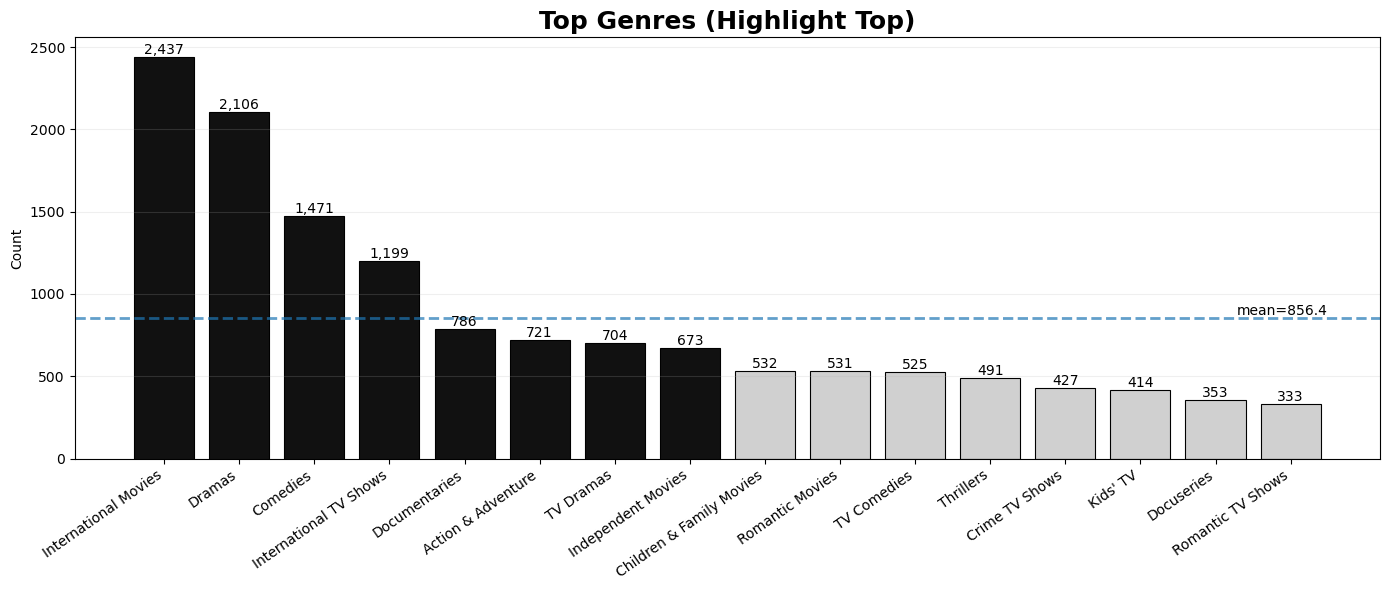

In [82]:
import numpy as np
import matplotlib.pyplot as plt

def fancy_bar_top(data, title, top_n=8, ylab="Count"):
    s = data.sort_values(ascending=False).head(top_n)
    rest = data.sort_values(ascending=False).iloc[top_n:top_n+8]  # 다음 8개 정도만 보여도 예쁨
    plot_s = pd.concat([s, rest])

    fig, ax = plt.subplots(figsize=(14, 6))
    vals = plot_s.values

    # 색: Top은 진하게, 나머지는 연하게
    colors = ["#111111"] * top_n + ["#d0d0d0"] * (len(plot_s) - top_n)
    bars = ax.bar(plot_s.index, vals, color=colors, edgecolor="black", linewidth=0.8)

    # 값 라벨
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2, b.get_height(),
                f"{int(b.get_height()):,}", ha="center", va="bottom", fontsize=10)

    # 평균선
    mean_v = np.mean(vals)
    ax.axhline(mean_v, linestyle="--", linewidth=2, alpha=0.7)
    ax.text(len(plot_s)-0.5, mean_v, f"mean={mean_v:.1f}", va="bottom", ha="right", fontsize=10)

    ax.set_title(title, fontsize=18, fontweight="bold")
    ax.set_ylabel(ylab)
    ax.set_xticklabels(plot_s.index, rotation=35, ha="right")
    ax.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    plt.show()

# 예: 장르 Top
genre_counts = df_genre["listed_in"].value_counts()
fancy_bar_top(genre_counts, "Top Genres (Highlight Top)")


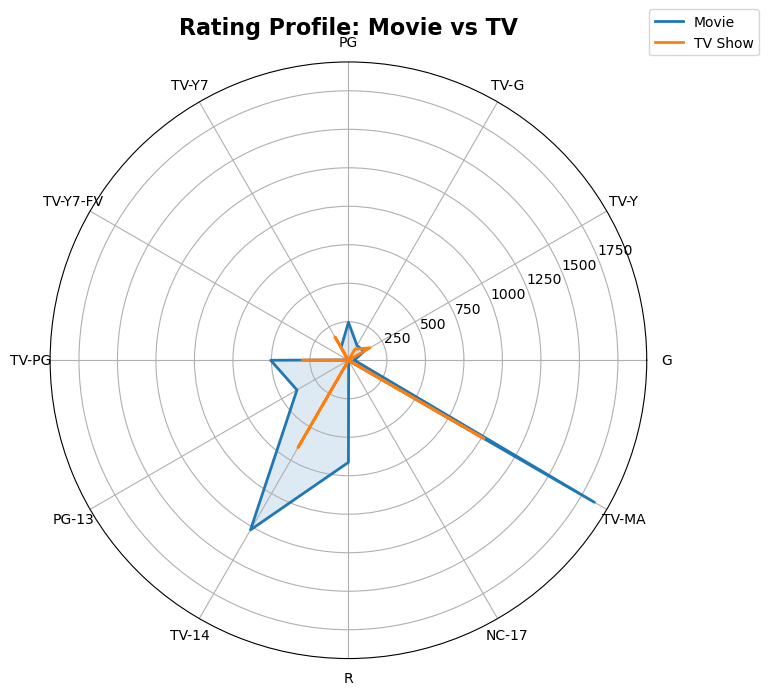

In [83]:
import numpy as np
import matplotlib.pyplot as plt

def radar_rating_compare(movie_counts, tv_counts, labels, title="Rating Profile: Movie vs TV"):
    # labels: 순서 리스트
    m = movie_counts.reindex(labels).fillna(0).values
    t = tv_counts.reindex(labels).fillna(0).values

    # 닫힌 도형 만들기(첫 값 다시 붙이기)
    m = np.append(m, m[0])
    t = np.append(t, t[0])

    angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False)
    angles = np.append(angles, angles[0])

    fig = plt.figure(figsize=(9, 7))
    ax = plt.subplot(111, polar=True)

    ax.plot(angles, m, linewidth=2, label="Movie")
    ax.fill(angles, m, alpha=0.15)

    ax.plot(angles, t, linewidth=2, label="TV Show")
    ax.fill(angles, t, alpha=0.15)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels)
    ax.set_title(title, fontsize=16, fontweight="bold", pad=20)
    ax.legend(loc="upper right", bbox_to_anchor=(1.2, 1.1))
    plt.tight_layout()
    plt.show()

# 예:
movie_counts = df_movies["rating"].value_counts()
tv_counts = df_tv["rating"].value_counts()
labels = rating_order_movie  # 라라맘 순서 사용 가능
radar_rating_compare(movie_counts, tv_counts, labels)


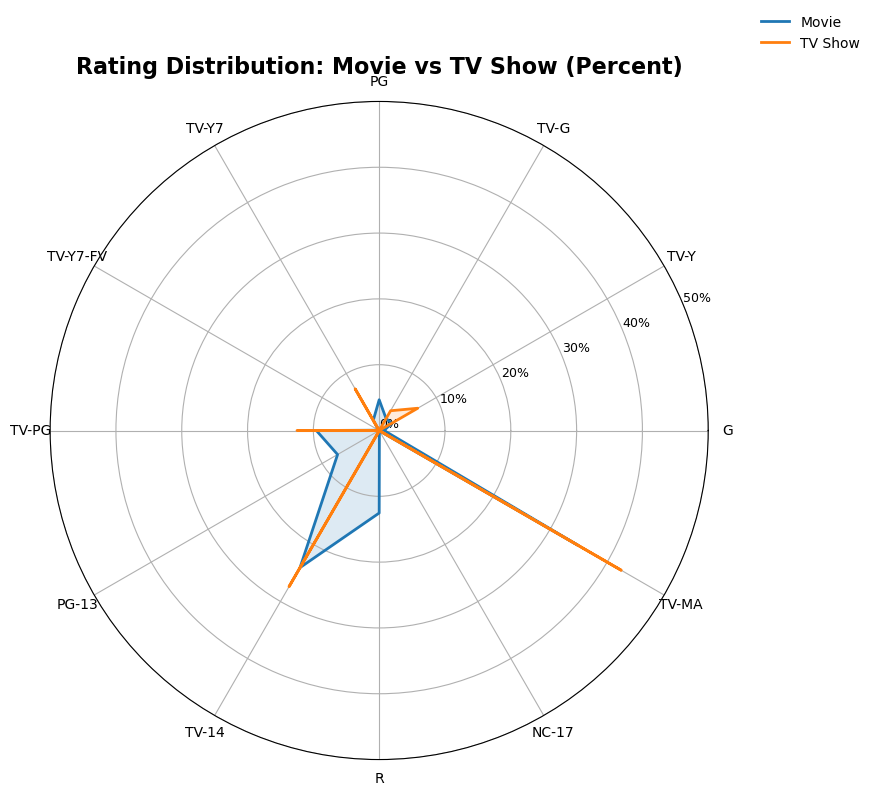

In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 라라맘이 정한 순서 그대로 사용
rating_order_movie = ['G', 'TV-Y', 'TV-G', 'PG', 'TV-Y7', 'TV-Y7-FV',
                      'TV-PG', 'PG-13', 'TV-14', 'R', 'NC-17', 'TV-MA']

# TV는 movie에 없는 등급도 있을 수 있어서, movie 기준 순서로 통일하면 비교가 깔끔함
labels = rating_order_movie  # ⭐ 한 장에서 비교하려면 라벨은 하나로 통일하는 게 좋아

# 1) rating 카운트 만들기 (show_id 있으면 nunique가 더 안전)
movie_counts = df_movies.groupby("rating")["show_id"].nunique()
tv_counts = df_tv.groupby("rating")["show_id"].nunique()

# 2) 순서 맞추고, 없는 등급은 0으로
movie_vals = movie_counts.reindex(labels).fillna(0).values
tv_vals = tv_counts.reindex(labels).fillna(0).values

# 3) “분포 비교”니까 퍼센트로 바꾸면 더 예쁘고 공정함 (강추)
movie_pct = movie_vals / movie_vals.sum() * 100
tv_pct = tv_vals / tv_vals.sum() * 100

# 4) 레이더 차트는 닫힌 도형이라 첫 값 다시 붙이기
movie_pct = np.append(movie_pct, movie_pct[0])
tv_pct = np.append(tv_pct, tv_pct[0])

angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False)
angles = np.append(angles, angles[0])

# 5) 그리기
fig = plt.figure(figsize=(10, 8))
ax = plt.subplot(111, polar=True)

# 선 + 채우기
ax.plot(angles, movie_pct, linewidth=2, label="Movie")
ax.fill(angles, movie_pct, alpha=0.15)

ax.plot(angles, tv_pct, linewidth=2, label="TV Show")
ax.fill(angles, tv_pct, alpha=0.15)

# 축 라벨
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=10)

# y축(반지름) 눈금: 퍼센트 기준
max_r = max(movie_pct.max(), tv_pct.max())
step = 5 if max_r <= 25 else 10
yticks = np.arange(0, max_r + step, step)
ax.set_yticks(yticks)
ax.set_yticklabels([f"{int(t)}%" for t in yticks], fontsize=9)

# 제목/범례
ax.set_title("Rating Distribution: Movie vs TV Show (Percent)", fontsize=16, fontweight="bold", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.15), frameon=False)

plt.tight_layout()
plt.show()
